In [29]:
# %pip install pandas numpy matplotlib seaborn scipy plotly ipywidgets

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("ball_result_data.csv")

print("Rows:", len(df))
print("Columns:", df.columns.tolist())

display(df.head())

Rows: 682326
Columns: ['event_date', 'game_mode', 'computedbowlinginput_pitching_point', 'computedbowlinginput_length_name', 'computedbowlinginput_line_name']


,event_date,game_mode,computedbowlinginput_pitching_point,computedbowlinginput_length_name,computedbowlinginput_line_name
0,17-09-2026,SinglePlayer,X=12.064 Y=492.397 Z=0.050,Full Length 2,Outside Off 7
1,17-09-2026,SinglePlayer,X=-4.282 Y=885.314 Z=0.050,Yorker 2,Leg 1
2,17-09-2026,SinglePlayer,X=5.206 Y=842.715 Z=0.050,Half Volley 1,Off 1
3,17-09-2026,SinglePlayer,X=-10.662 Y=880.234 Z=0.050,Half Volley 1,Leg 1
4,17-09-2026,SinglePlayer,X=22.709 Y=883.125 Z=0.050,Half Volley 1,Outside Off 7


In [31]:
coords = df["computedbowlinginput_pitching_point"].str.extract(
    r"X=([-+]?\d*\.?\d+)\s+Y=([-+]?\d*\.?\d+)"
)

df["X"] = -pd.to_numeric(coords[0], errors="coerce")
df["Y"] = pd.to_numeric(coords[1], errors="coerce")

df = df.dropna(subset=["X", "Y"])

print("Valid coordinate rows:", len(df))

display(
    df[
        [
            "computedbowlinginput_pitching_point",
            "X",
            "Y",
            "computedbowlinginput_length_name",
            "computedbowlinginput_line_name"
        ]
    ].head(10)
)

Valid coordinate rows: 682325


,computedbowlinginput_pitching_point,X,Y,computedbowlinginput_length_name,computedbowlinginput_line_name
0,X=12.064 Y=492.397 Z=0.050,-12.064,492.397,Full Length 2,Outside Off 7
1,X=-4.282 Y=885.314 Z=0.050,4.282,885.314,Yorker 2,Leg 1
2,X=5.206 Y=842.715 Z=0.050,-5.206,842.715,Half Volley 1,Off 1
3,X=-10.662 Y=880.234 Z=0.050,10.662,880.234,Half Volley 1,Leg 1
4,X=22.709 Y=883.125 Z=0.050,-22.709,883.125,Half Volley 1,Outside Off 7
5,X=-13.648 Y=827.557 Z=0.050,13.648,827.557,Half Volley 1,Outside Leg 1
6,X=-9.057 Y=895.303 Z=0.050,9.057,895.303,Yorker 2,Leg 1
7,X=-15.547 Y=821.082 Z=0.050,15.547,821.082,Half Volley 1,Outside Leg 1
8,X=23.459 Y=864.544 Z=0.050,-23.459,864.544,Half Volley 1,Outside Off 6
9,X=-8.216 Y=92.009 Z=0.050,8.216,92.009,Back of Length 2,Leg 1


In [32]:
print("X range:", df["X"].min(), "to", df["X"].max())
print("Y range:", df["Y"].min(), "to", df["Y"].max())

display(df[["X", "Y"]].describe())

X range: -130.243 to 127.659
Y range: -71.285 to 950.374


,X,Y
count,682325.000000,682325.000000
mean,-10.629043,550.102293
std,33.405607,238.486840
min,-130.243000,-71.285000
25%,-31.981000,453.197000
50%,-6.747000,507.825000
75%,6.859000,768.948000
max,127.659000,950.374000


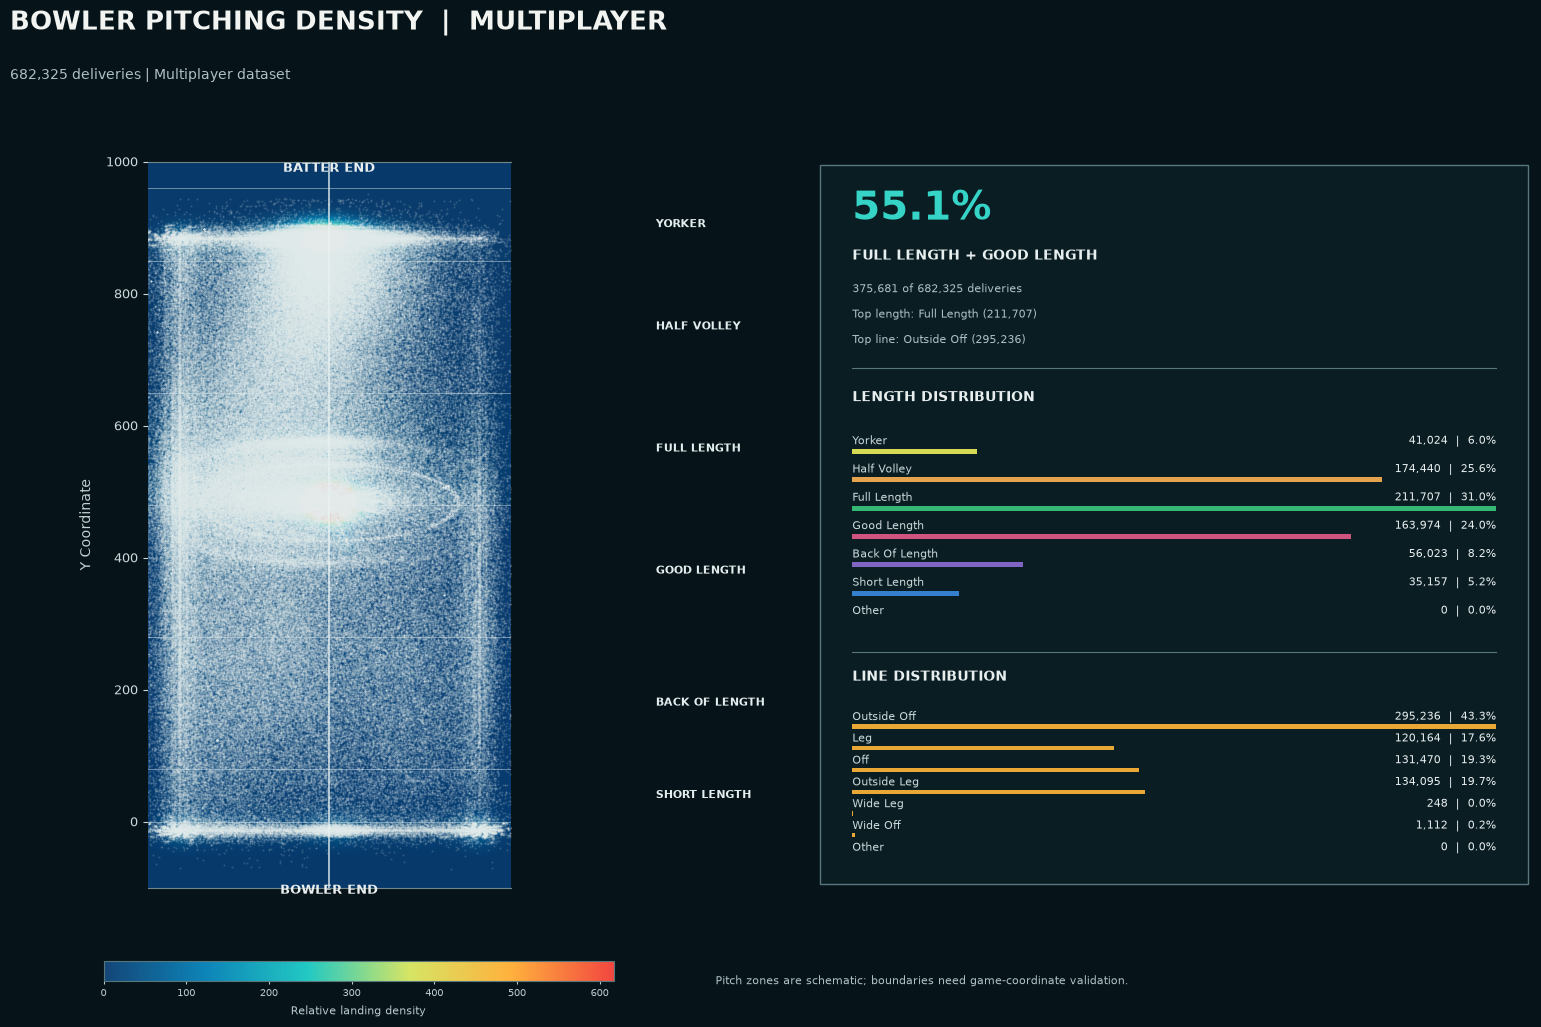

In [33]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter
from matplotlib.patches import Rectangle

# ==========================================
# 1. DATA PREPARATION
# ==========================================

plot_df = df.dropna(subset=["X", "Y"]).copy()

length_col = "computedbowlinginput_length_name"
line_col = "computedbowlinginput_line_name"
total = len(plot_df)

def get_length_group(value):
    value = str(value).lower()
    for name in ["yorker", "half volley", "full length",
                 "good length", "back of length", "short length"]:
        if name in value:
            return name.title()
    return "Other"

def get_line_group(value):
    value = str(value).lower()
    if "wide leg" in value:
        return "Wide Leg"
    if "wide off" in value:
        return "Wide Off"
    if "outside off" in value:
        return "Outside Off"
    if "outside leg" in value:
        return "Outside Leg"
    if "leg" in value:
        return "Leg"
    if "off" in value:
        return "Off"
    return "Other"

plot_df["Length Group"] = plot_df[length_col].apply(get_length_group)
plot_df["Line Group"] = plot_df[line_col].apply(get_line_group)

# Robust display limits
x_limit = max(25, np.percentile(np.abs(plot_df["X"]), 99.5))
y_min = min(-75, np.floor(plot_df["Y"].min() / 50) * 50)
y_max = max(960, np.ceil(plot_df["Y"].max() / 50) * 50)

visible = plot_df[
    plot_df["X"].between(-x_limit, x_limit) &
    plot_df["Y"].between(y_min, y_max)
].copy()

# ==========================================
# 2. DENSITY GRID
# ==========================================

density, x_edges, y_edges = np.histogram2d(
    visible["X"], visible["Y"],
    bins=[100, 160],
    range=[[-x_limit, x_limit], [y_min, y_max]]
)

smooth_density = gaussian_filter(density.T, sigma=2.2)

cmap = LinearSegmentedColormap.from_list(
    "bowling_density",
    ["#073b70", "#007eb4", "#16c6c0",
     "#d3e45c", "#ffad32", "#f23d35"]
)

# ==========================================
# 3. FIGURE LAYOUT
# ==========================================

fig = plt.figure(
    figsize=(17, 11),
    facecolor="#061419"
)

gs = fig.add_gridspec(
    1, 3,
    width_ratios=[1.0, 0.24, 1.12],
    left=0.065,
    right=0.96,
    top=0.82,
    bottom=0.16,
    wspace=0.015
)

ax = fig.add_subplot(gs[0, 0])
zone_ax = fig.add_subplot(gs[0, 1], sharey=ax)
panel = fig.add_subplot(gs[0, 2])

for a in [ax, zone_ax, panel]:
    a.set_facecolor("#091d23")

# ==========================================
# 4. PITCH HEATMAP
# ==========================================

zones = [
    (0, 80, "SHORT LENGTH", "#285ca8"),
    (80, 280, "BACK OF LENGTH", "#6450a5"),
    (280, 480, "GOOD LENGTH", "#a54d76"),
    (480, 650, "FULL LENGTH", "#23865c"),
    (650, 850, "HALF VOLLEY", "#967044"),
    (850, 960, "YORKER", "#858b3b")
]

for low, high, label, color in zones:
    ax.axhspan(
        low, high,
        color=color,
        alpha=0.43,
        zorder=0
    )

heat = ax.imshow(
    smooth_density,
    origin="lower",
    extent=[
        x_edges[0], x_edges[-1],
        y_edges[0], y_edges[-1]
    ],
    aspect="auto",
    cmap=cmap,
    interpolation="bilinear",
    alpha=0.95,
    vmin=0,
    vmax=max(1, np.percentile(smooth_density, 99.5)),
    zorder=2
)

ax.scatter(
    visible["X"], visible["Y"],
    s=2,
    color="#e4eeee",
    alpha=0.18,
    linewidths=0,
    zorder=3
)

# Centre pitch line
ax.axvline(
    0,
    color="#e9f2f2",
    linewidth=1.2,
    alpha=0.85,
    zorder=4
)

for y in [0, 80, 280, 480, 650, 850, 960]:
    ax.axhline(
        y,
        color="#dce8e8",
        linewidth=0.65,
        alpha=0.5,
        zorder=4
    )

ax.text(
    0, 980, "BATTER END",
    color="#e9eeee",
    ha="center", va="bottom",
    fontsize=9, fontweight="bold",
    clip_on=False
)

ax.text(
    0, -95, "BOWLER END",
    color="#e9eeee",
    ha="center", va="top",
    fontsize=9, fontweight="bold",
    clip_on=False
)

ax.set_xlim(-x_limit, x_limit)
ax.set_ylim(y_min, y_max)
ax.set_box_aspect(2.0)

ax.set_xlabel("")
ax.set_xticks([])
ax.tick_params(axis="x", bottom=False, top=False)

ax.set_ylabel("Y Coordinate", color="#c4d1d3", labelpad=9)

ax.tick_params(colors="#cbd7d9", labelsize=9)
ax.grid(False)

for spine in ax.spines.values():
    spine.set_color("#71878a")
    spine.set_linewidth(0.8)

# Keep only the centre vertical line.
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)

# ==========================================
# 5. SEPARATE ZONE LABELS
# ==========================================

zone_ax.set_xlim(0, 1)
zone_ax.set_ylim(y_min, y_max)
zone_ax.axis("off")

for low, high, label, color in zones:
    zone_ax.text(
        0.0,
        (low + high) / 2,
        label,
        color="#e5eeee",
        fontsize=8,
        fontweight="bold",
        ha="left",
        va="center"
    )

# ==========================================
# 6. STATISTICS PANEL
# ==========================================

panel.set_xlim(0, 1)
panel.set_ylim(0, 1)
panel.axis("off")

panel.add_patch(Rectangle(
    (0.005, 0.005), 0.99, 0.99,
    transform=panel.transAxes,
    facecolor="#091d23",
    edgecolor="#57777c",
    linewidth=1.0
))

# Full-length / good-length summary
length_counts = plot_df["Length Group"].value_counts()
line_counts = plot_df["Line Group"].value_counts()
target_lengths = ["Full Length", "Good Length"]
target_count = int(length_counts.reindex(target_lengths, fill_value=0).sum())
target_pct = target_count / total * 100 if total else 0
top_length = length_counts.idxmax()
top_line = line_counts.idxmax()

panel.text(
    0.05, 0.92,
    f"{target_pct:.1f}%",
    color="#35d4c7",
    fontsize=29,
    fontweight="bold"
)

panel.text(
    0.05, 0.865,
    "FULL LENGTH + GOOD LENGTH",
    color="#e7eeee",
    fontsize=10,
    fontweight="bold"
)

panel.text(
    0.05, 0.82,
    f"{target_count:,} of {total:,} deliveries",
    color="#afc1c4",
    fontsize=8
)

panel.text(
    0.05, 0.785,
    f"Top length: {top_length} ({int(length_counts[top_length]):,})",
    color="#afc1c4", fontsize=8
)

panel.text(
    0.05, 0.75,
    f"Top line: {top_line} ({int(line_counts[top_line]):,})",
    color="#afc1c4", fontsize=8
)

panel.plot(
    [0.05, 0.95], [0.715, 0.715],
    color="#57777c",
    linewidth=0.8
)

# Length distribution
panel.text(
    0.05, 0.67,
    "LENGTH DISTRIBUTION",
    color="#e8eeee",
    fontsize=10,
    fontweight="bold"
)

length_order = [
    "Yorker", "Half Volley", "Full Length",
    "Good Length", "Back Of Length",
    "Short Length", "Other"
]

length_colors = [
    "#d5d953", "#e6a34e", "#36b875",
    "#cf547f", "#8065c4", "#347fce",
    "#819194"
]

max_length = max(1, length_counts.max())

for i, (name, color) in enumerate(zip(length_order, length_colors)):
    y = 0.615 - i * 0.039
    count = int(length_counts.get(name, 0))
    pct = count / total * 100 if total else 0

    panel.text(
        0.05, y,
        name,
        color="#cbd8d9",
        fontsize=8,
        va="center"
    )

    panel.text(
        0.95, y,
        f"{count:,}  |  {pct:.1f}%",
        color="#e8eeee",
        fontsize=8,
        ha="right",
        va="center"
    )

    panel.add_patch(Rectangle(
        (0.05, y - 0.018),
        0.90 * count / max_length,
        0.007,
        transform=panel.transAxes,
        facecolor=color,
        edgecolor="none"
    ))

# Separator
panel.plot(
    [0.05, 0.95], [0.325, 0.325],
    color="#57777c",
    linewidth=0.8
)

# Line distribution
panel.text(
    0.05, 0.285,
    "LINE DISTRIBUTION",
    color="#e8eeee",
    fontsize=10,
    fontweight="bold"
)

line_order = [
    "Outside Off", "Leg", "Off",
    "Outside Leg", "Wide Leg", "Wide Off", "Other"
]

max_line = max(1, line_counts.max())

for i, name in enumerate(line_order):
    y = 0.235 - i * 0.030
    count = int(line_counts.get(name, 0))
    pct = count / total * 100 if total else 0

    panel.text(
        0.05, y,
        name,
        color="#cbd8d9",
        fontsize=8,
        va="center"
    )

    panel.text(
        0.95, y,
        f"{count:,}  |  {pct:.1f}%",
        color="#e8eeee",
        fontsize=8,
        ha="right",
        va="center"
    )

    panel.add_patch(Rectangle(
        (0.05, y - 0.016),
        0.90 * count / max_line,
        0.006,
        transform=panel.transAxes,
        facecolor="#e9a735",
        edgecolor="none"
    ))

# ==========================================
# 7. TITLE AND COLOR SCALE
# ==========================================

fig.text(
    0.065, 0.94,
    "BOWLER PITCHING DENSITY  |  MULTIPLAYER",
    color="#f2f4f1",
    fontsize=19,
    fontweight="bold"
)

fig.text(
    0.065, 0.895,
    f"{total:,} deliveries | Multiplayer dataset",
    color="#afc1c4",
    fontsize=10
)

# Dedicated colorbar area, outside the charts
cax = fig.add_axes([0.12, 0.075, 0.30, 0.018])

cbar = fig.colorbar(
    heat,
    cax=cax,
    orientation="horizontal"
)

cbar.set_label(
    "Relative landing density",
    color="#b9c9cc",
    fontsize=8,
    labelpad=5
)

cbar.ax.tick_params(
    colors="#b9c9cc",
    labelsize=7,
    length=2
)

cbar.outline.set_edgecolor("#57777c")

fig.text(
    0.48, 0.075,
    "Pitch zones are schematic; boundaries need game-coordinate validation.",
    color="#afc1c4",
    fontsize=8,
    va="center"
)

plt.show()

In [ ]:
import ipywidgets as widgets
from IPython.display import display

formation_options = ["All"] + sorted(
    df["event_date"].dropna().astype(str).unique().tolist()
)

mode_options = ["All"] + sorted(
    df["game_mode"].dropna().astype(str).unique().tolist()
)

formation_dropdown = widgets.Dropdown(
    options=formation_options,
    value="All",
    description="Date:",
    layout=widgets.Layout(width="450px")
)

mode_dropdown = widgets.Dropdown(
    options=mode_options,
    value="All",
    description="Game Mode:",
    layout=widgets.Layout(width="450px")
)

display(formation_dropdown, mode_dropdown)

Dropdown(description='Date:', layout=Layout(width='450px'), options=('All', '09-09-2026', '10-09-2026', '11-09…

Dropdown(description='Game Mode:', layout=Layout(width='450px'), options=('All', 'Multiplayer', 'SinglePlayer'…

In [35]:
from IPython.display import display, clear_output
from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
import numpy as np


def create_dashboard(filtered_df, formation, mode):
    length_col = "computedbowlinginput_length_name"
    line_col = "computedbowlinginput_line_name"

    plot_df = filtered_df.dropna(subset=["X", "Y"]).copy()
    if plot_df.empty:
        print("No deliveries with valid pitch coordinates for this selection.")
        return

    total = len(plot_df)

    def get_length_group(value):
        value = str(value).lower()
        for name in [
            "yorker", "half volley", "full length",
            "good length", "back of length", "short length"
        ]:
            if name in value:
                return name.title()
        return "Other"

    def get_line_group(value):
        value = str(value).lower()
        if "wide leg" in value:
            return "Wide Leg"
        if "wide off" in value:
            return "Wide Off"
        if "outside off" in value:
            return "Outside Off"
        if "outside leg" in value:
            return "Outside Leg"
        if "leg" in value:
            return "Leg"
        if "off" in value:
            return "Off"
        return "Other"

    plot_df["Length Group"] = plot_df[length_col].apply(get_length_group)
    plot_df["Line Group"] = plot_df[line_col].apply(get_line_group)

    x_limit = max(25, np.percentile(np.abs(plot_df["X"]), 99.5))
    y_min = min(-75, np.floor(plot_df["Y"].min() / 50) * 50)
    y_max = max(960, np.ceil(plot_df["Y"].max() / 50) * 50)

    visible = plot_df[
        plot_df["X"].between(-x_limit, x_limit)
        & plot_df["Y"].between(y_min, y_max)
    ].copy()

    density, x_edges, y_edges = np.histogram2d(
        visible["X"],
        visible["Y"],
        bins=[100, 160],
        range=[[-x_limit, x_limit], [y_min, y_max]],
    )
    smooth_density = gaussian_filter(density.T, sigma=2.2)

    cmap = LinearSegmentedColormap.from_list(
        "bowling_density",
        ["#073b70", "#007eb4", "#16c6c0",
         "#d3e45c", "#ffad32", "#f23d35"],
    )

    fig = plt.figure(figsize=(17, 11), facecolor="#061419")
    gs = fig.add_gridspec(
        1, 3,
        width_ratios=[1.0, 0.24, 1.12],
        left=0.065, right=0.96, top=0.82, bottom=0.16, wspace=0.015,
    )
    ax = fig.add_subplot(gs[0, 0])
    zone_ax = fig.add_subplot(gs[0, 1], sharey=ax)
    panel = fig.add_subplot(gs[0, 2])

    for a in (ax, zone_ax, panel):
        a.set_facecolor("#091d23")

    zones = [
        (0, 80, "SHORT LENGTH", "#285ca8"),
        (80, 280, "BACK OF LENGTH", "#6450a5"),
        (280, 480, "GOOD LENGTH", "#a54d76"),
        (480, 650, "FULL LENGTH", "#23865c"),
        (650, 850, "HALF VOLLEY", "#967044"),
        (850, 960, "YORKER", "#858b3b"),
    ]

    for low, high, label, color in zones:
        ax.axhspan(low, high, color=color, alpha=0.43, zorder=0)

    heat = ax.imshow(
        smooth_density,
        origin="lower",
        extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]],
        aspect="auto",
        cmap=cmap,
        interpolation="bilinear",
        alpha=0.95,
        vmin=0,
        vmax=max(1, np.percentile(smooth_density, 99.5)),
        zorder=2,
    )
    ax.scatter(
        visible["X"], visible["Y"],
        s=2, color="#e4eeee", alpha=0.18, linewidths=0, zorder=3,
    )

    # Centre pitch line
    ax.axvline(0, color="#e9f2f2", linewidth=1.2, alpha=0.85, zorder=4)
    for y in [0, 80, 280, 480, 650, 850, 960]:
        ax.axhline(y, color="#dce8e8", linewidth=0.65, alpha=0.5, zorder=4)

    ax.text(0, 980, "BATTER END", color="#e9eeee",
            ha="center", va="bottom", fontsize=9, fontweight="bold",
            clip_on=False)
    ax.text(0, -95, "BOWLER END", color="#e9eeee",
            ha="center", va="top", fontsize=9, fontweight="bold",
            clip_on=False)
    ax.set_xlim(-x_limit, x_limit)
    ax.set_ylim(y_min, y_max)
    ax.set_box_aspect(2.0)
    ax.set_xticks([])
    ax.set_ylabel("Y Coordinate", color="#c4d1d3", labelpad=9)
    ax.tick_params(colors="#cbd7d9", labelsize=9)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_color("#71878a")
        spine.set_linewidth(0.8)
    # Keep only the centre vertical line.
    ax.spines["left"].set_visible(False)
    ax.spines["right"].set_visible(False)

    zone_ax.set_xlim(0, 1)
    zone_ax.set_ylim(y_min, y_max)
    zone_ax.axis("off")
    for low, high, label, color in zones:
        zone_ax.text(0.0, (low + high) / 2, label,
                     color="#e5eeee", fontsize=8, fontweight="bold",
                     ha="left", va="center")

    panel.set_xlim(0, 1)
    panel.set_ylim(0, 1)
    panel.axis("off")
    panel.add_patch(Rectangle(
        (0.005, 0.005), 0.99, 0.99, transform=panel.transAxes,
        facecolor="#091d23", edgecolor="#57777c", linewidth=1.0,
    ))
    # Full-length / good-length summary
    length_counts = plot_df["Length Group"].value_counts()
    line_counts = plot_df["Line Group"].value_counts()
    target_lengths = ["Full Length", "Good Length"]
    target_count = int(length_counts.reindex(target_lengths, fill_value=0).sum())
    target_pct = target_count / total * 100 if total else 0
    top_length = length_counts.idxmax()
    top_line = line_counts.idxmax()

    panel.text(0.05, 0.92, f"{target_pct:.1f}%", color="#35d4c7",
               fontsize=29, fontweight="bold")
    panel.text(0.05, 0.865, "FULL LENGTH + GOOD LENGTH", color="#e7eeee",
               fontsize=10, fontweight="bold")
    panel.text(0.05, 0.82, f"{target_count:,} of {total:,} deliveries",
               color="#afc1c4", fontsize=8)
    panel.text(0.05, 0.785,
               f"Top length: {top_length} ({int(length_counts[top_length]):,})",
               color="#afc1c4", fontsize=8)
    panel.text(0.05, 0.75,
               f"Top line: {top_line} ({int(line_counts[top_line]):,})",
               color="#afc1c4", fontsize=8)
    panel.plot([0.05, 0.95], [0.715, 0.715], color="#57777c", linewidth=0.8)

    length_order = [
        "Yorker", "Half Volley", "Full Length", "Good Length",
        "Back Of Length", "Short Length", "Other",
    ]
    length_colors = [
        "#d5d953", "#e6a34e", "#36b875", "#cf547f",
        "#8065c4", "#347fce", "#819194",
    ]
    max_length = max(1, length_counts.max())
    panel.text(0.05, 0.67, "LENGTH DISTRIBUTION", color="#e8eeee",
               fontsize=10, fontweight="bold")

    for i, (name, color) in enumerate(zip(length_order, length_colors)):
        y = 0.615 - i * 0.039
        count = int(length_counts.get(name, 0))
        pct = count / total * 100
        panel.text(0.05, y, name, color="#cbd8d9", fontsize=8, va="center")
        panel.text(0.95, y, f"{count:,}  |  {pct:.1f}%",
                   color="#e8eeee", fontsize=8, ha="right", va="center")
        panel.add_patch(Rectangle(
            (0.05, y - 0.018), 0.90 * count / max_length, 0.007,
            transform=panel.transAxes, facecolor=color, edgecolor="none",
        ))

    panel.plot([0.05, 0.95], [0.325, 0.325], color="#57777c", linewidth=0.8)
    line_order = [
        "Outside Off", "Leg", "Off", "Outside Leg",
        "Wide Leg", "Wide Off", "Other",
    ]
    max_line = max(1, line_counts.max())
    panel.text(0.05, 0.285, "LINE DISTRIBUTION", color="#e8eeee",
               fontsize=10, fontweight="bold")

    for i, name in enumerate(line_order):
        y = 0.235 - i * 0.030
        count = int(line_counts.get(name, 0))
        pct = count / total * 100
        panel.text(0.05, y, name, color="#cbd8d9", fontsize=8, va="center")
        panel.text(0.95, y, f"{count:,}  |  {pct:.1f}%",
                   color="#e8eeee", fontsize=8, ha="right", va="center")
        panel.add_patch(Rectangle(
            (0.05, y - 0.016), 0.90 * count / max_line, 0.006,
            transform=panel.transAxes, facecolor="#e9a735", edgecolor="none",
        ))

    fig.text(
        0.065, 0.94,
        f"BOWLER PITCHING DENSITY  |  DATE: {formation}  |  MODE: {mode}",
        color="#f2f4f1", fontsize=19, fontweight="bold"
    )
    fig.text(0.065, 0.895, f"{total:,} deliveries",
             color="#afc1c4", fontsize=10)

    cax = fig.add_axes([0.12, 0.075, 0.30, 0.018])
    cbar = fig.colorbar(heat, cax=cax, orientation="horizontal")
    cbar.set_label("Relative landing density", color="#b9c9cc",
                   fontsize=8, labelpad=5)
    cbar.ax.tick_params(colors="#b9c9cc", labelsize=7, length=2)
    cbar.outline.set_edgecolor("#57777c")
    fig.text(0.48, 0.075,
             "Pitch zones are schematic; boundaries need game-coordinate validation.",
             color="#afc1c4", fontsize=8, va="center")

    plt.show()
    plt.close(fig)


def update_dashboard(formation, mode):
    filtered_df = df.copy()

    if formation != "All":
        filtered_df = filtered_df[
            filtered_df["event_date"].astype(str) == formation
        ]

    if mode != "All":
        filtered_df = filtered_df[
            filtered_df["game_mode"].astype(str) == mode
        ]

    print(f"Deliveries: {len(filtered_df):,}")

    create_dashboard(filtered_df, formation, mode)


out = widgets.interactive_output(
    update_dashboard,
    {
        "formation": formation_dropdown,
        "mode": mode_dropdown,
    },
)
display(out)

Output()

In [36]:
# ============================================================
# WAGON WHEEL DATA — CHANGE ONLY THIS ARRAY FOR FUTURE DATASETS
# ============================================================

title_text = "CB1 MULTIPLAYER SIXES (09 ~ 12 Sep)"

values = [
    33.0,   # 0-45
    15.6,   # 045-90
    1.7,    # 090-135
    0.0,    # 135-180
    0.3,    # 180-225
    5.2,    # 225-270
    21.2,   # 270-315
    22.9    # 315-360
]

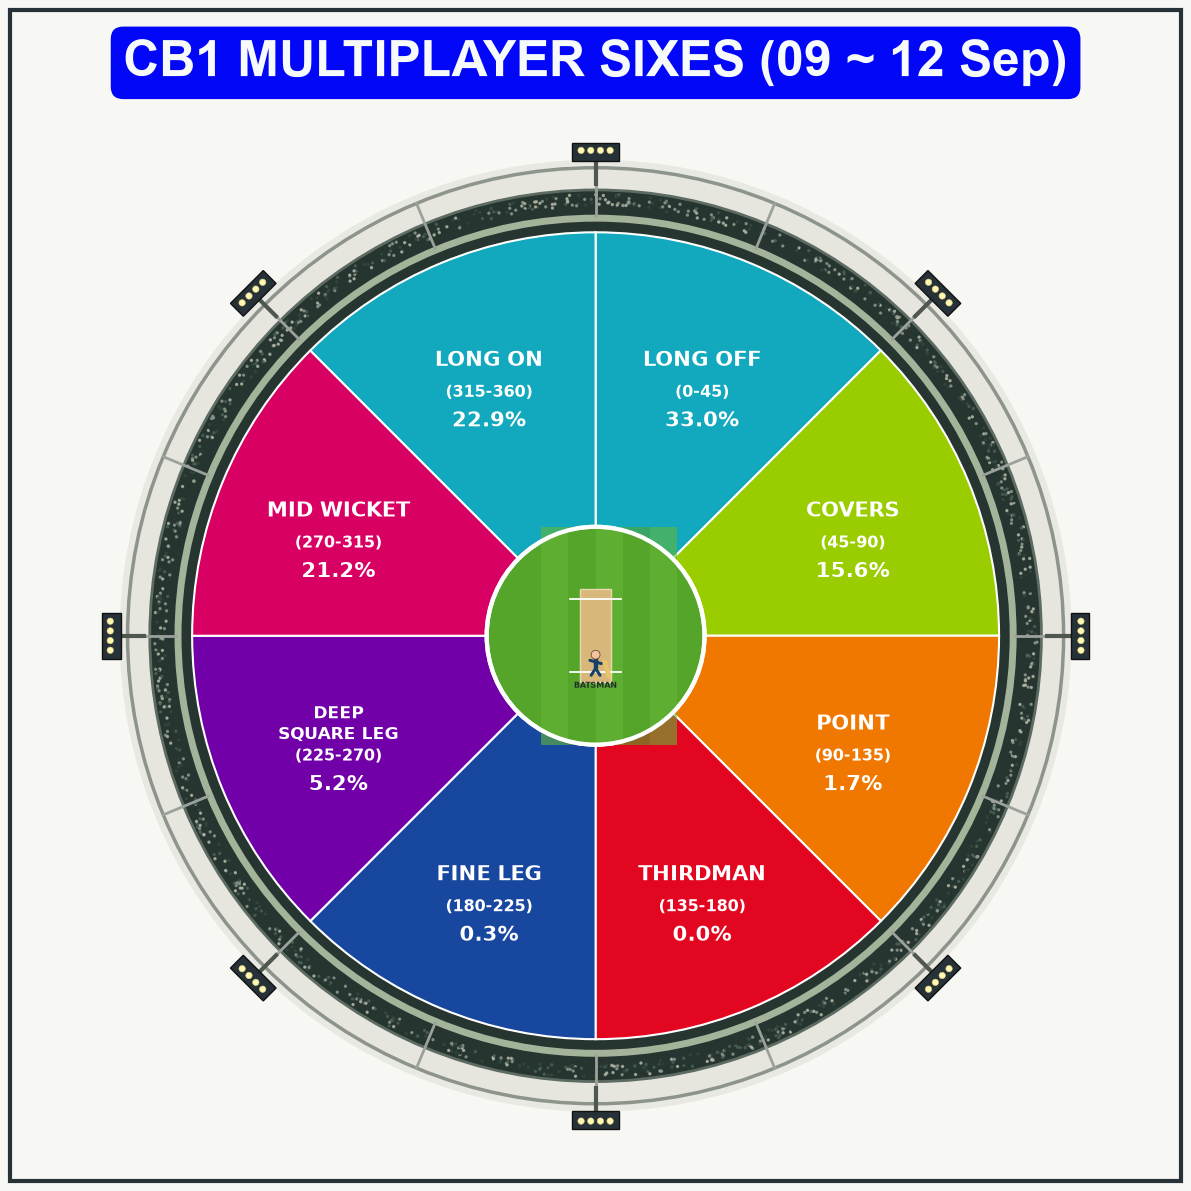

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge, Circle, Rectangle, Polygon



# ============================================================
# FIELDING POSITIONS + ANGLE MAPPING
# ============================================================

segments = [
    ("LONG OFF",         "0-45"),
    ("COVERS",           "45-90"),
    ("POINT",            "90-135"),
    ("THIRDMAN",         "135-180"),
    ("FINE LEG",         "180-225"),
    ("DEEP\nSQUARE LEG", "225-270"),
    ("MID WICKET",       "270-315"),
    ("LONG ON",          "315-360"),
]


# ============================================================
# COLORS
# ============================================================

colors = [
    "#12A8BD",   # 0-45
    "#9ACD00",   # 45-90
    "#F07800",   # 90-135
    "#E30620",   # 135-180
    "#17479E",   # 180-225
    "#7200A8",   # 225-270
    "#D90063",   # 270-315
    "#12A8BD",   # 315-360
]


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(12, 12))

fig.patch.set_facecolor("#f7f7f3")
ax.set_facecolor("#f7f7f3")

ax.set_aspect("equal")
ax.axis("off")


# ============================================================
# OUTER PAVILION / STADIUM
# ============================================================

# Outer shadow
ax.add_patch(
    Circle(
        (0, 0),
        1.18,
        facecolor="#d9d9d2",
        edgecolor="none",
        alpha=0.45,
        zorder=0
    )
)


# Outer pavilion
ax.add_patch(
    Circle(
        (0, 0),
        1.16,
        facecolor="#e6e6df",
        edgecolor="#8d948b",
        linewidth=2.5,
        zorder=1
    )
)


# Dark spectator ring
ax.add_patch(
    Circle(
        (0, 0),
        1.105,
        facecolor="#26352f",
        edgecolor="#5d6b62",
        linewidth=2,
        zorder=2
    )
)


# ============================================================
# PAVILION / CROWD TEXTURE
# ============================================================

np.random.seed(7)

n_people = 1300

angles = np.random.uniform(
    0,
    2 * np.pi,
    n_people
)

radii = np.random.uniform(
    1.065,
    1.095,
    n_people
)

x = radii * np.cos(angles)
y = radii * np.sin(angles)

crowd_colors = np.random.choice(
    [
        "#24352F",
        "#4B6258",
        "#8C9A8E",
        "#B7B9A8",
        "#35483F"
    ],
    size=n_people
)

ax.scatter(
    x,
    y,
    s=2,
    c=crowd_colors,
    alpha=0.75,
    zorder=3
)


# Inner pavilion border
ax.add_patch(
    Circle(
        (0, 0),
        1.035,
        facecolor="none",
        edgecolor="#a4b49b",
        linewidth=5,
        zorder=4
    )
)


# ============================================================
# PAVILION SUPPORT SEGMENTS
# ============================================================

for angle in np.arange(0, 360, 22.5):

    theta = np.deg2rad(angle)

    x1 = 1.04 * np.cos(theta)
    y1 = 1.04 * np.sin(theta)

    x2 = 1.16 * np.cos(theta)
    y2 = 1.16 * np.sin(theta)

    ax.plot(
        [x1, x2],
        [y1, y2],
        color="#9ba29b",
        linewidth=2,
        zorder=5
    )


# ============================================================
# FLOODLIGHTS
# ============================================================

floodlight_angles = np.arange(0, 360, 45)

for angle in floodlight_angles:

    # IMPORTANT:
    # Convert our cricket angle system
    # (0° = top, clockwise)
    # into matplotlib coordinates
    theta = np.deg2rad(90 - angle)

    x = 1.20 * np.cos(theta)
    y = 1.20 * np.sin(theta)

    # Pole
    pole_x = 1.12 * np.cos(theta)
    pole_y = 1.12 * np.sin(theta)

    ax.plot(
        [pole_x, x],
        [pole_y, y],
        color="#505750",
        linewidth=3,
        zorder=8
    )

    # Floodlight bar: aligned perpendicular to the pole, with four lamps.
    tangent = np.array([-np.sin(theta), np.cos(theta)])
    radial = np.array([np.cos(theta), np.sin(theta)])
    light_w = 0.115
    light_h = 0.045
    centre = np.array([x, y])
    corners = [
        centre - tangent * light_w / 2 - radial * light_h / 2,
        centre + tangent * light_w / 2 - radial * light_h / 2,
        centre + tangent * light_w / 2 + radial * light_h / 2,
        centre - tangent * light_w / 2 + radial * light_h / 2,
    ]
    ax.add_patch(Polygon(corners, closed=True, facecolor="#263238",
                         edgecolor="#111", linewidth=1, zorder=9))

    for offset in [-0.036, -0.012, 0.012, 0.036]:
        lamp = centre + tangent * offset + radial * 0.003
        ax.add_patch(Circle(lamp, 0.008, facecolor="#FFF7B2",
                            edgecolor="#D1C77C", linewidth=0.4, zorder=10))


# ============================================================
# MAIN 8-WAY CRICKET WHEEL
#
# IMPORTANT:
#
# Our angle system:
#
#       0°
#        |
#        | clockwise
#        ↓
#
# Matplotlib:
#       0° = right
#       angles increase counter-clockwise
#
# Conversion:
#
# matplotlib_angle = 90 - cricket_angle
#
# ============================================================

outer_radius = 1.00
inner_radius = 0.27


for i, ((name, angle_label), value) in enumerate(
    zip(segments, values)
):

    # Extract the angle limits
    start_angle = i * 45
    end_angle = (i + 1) * 45

    # Convert cricket coordinates
    # (0° north, clockwise)
    # to matplotlib coordinates
    #
    # Example:
    # 0-45 becomes matplotlib 45-90
    #
    mpl_start = 90 - end_angle
    mpl_end = 90 - start_angle

    wedge = Wedge(
        (0, 0),
        outer_radius,
        mpl_start,
        mpl_end,
        width=outer_radius - inner_radius,
        facecolor=colors[i],
        edgecolor="white",
        linewidth=1.5,
        zorder=20
    )

    ax.add_patch(wedge)


# ============================================================
# CENTRE FIELD
# ============================================================

ax.add_patch(
    Circle(
        (0, 0),
        inner_radius,
        facecolor="#55A52A",
        edgecolor="white",
        linewidth=3,
        zorder=30
    )
)


# ============================================================
# FIELD STRIPES
# ============================================================

stripe_width = inner_radius / 4

for i in range(-2, 3):

    x_start = i * stripe_width

    ax.add_patch(
        Rectangle(
            (
                x_start,
                -inner_radius
            ),
            stripe_width,
            inner_radius * 2,
            facecolor=(
                "#65B637"
                if i % 2 == 0
                else "#55A52A"
            ),
            edgecolor="none",
            alpha=0.6,
            zorder=31
        )
    )


# Re-draw centre circle border
ax.add_patch(
    Circle(
        (0, 0),
        inner_radius,
        facecolor="none",
        edgecolor="white",
        linewidth=3,
        zorder=35
    )
)


# ============================================================
# CRICKET PITCH
# ============================================================

pitch_width = 0.075
pitch_height = 0.23


# Pitch
ax.add_patch(
    Rectangle(
        (
            -pitch_width / 2,
            -pitch_height / 2
        ),
        pitch_width,
        pitch_height,
        facecolor="#D7B87A",
        edgecolor="#E8D8AA",
        linewidth=1,
        zorder=40
    )
)


# Creases
for y in [
    -pitch_height / 2 + 0.025,
    pitch_height / 2 - 0.025
]:

    ax.plot(
        [
            -pitch_width / 2 - 0.025,
            pitch_width / 2 + 0.025
        ],
        [y, y],
        color="white",
        linewidth=1.3,
        zorder=41
    )


# ============================================================
# PLAYERS ON THE PITCH
# ============================================================

def draw_batsman(x, y, facing=1):
    """Draw a compact batsman icon at the lower crease."""
    kit_color = "#173F67"

    # Head, body, arms and legs
    ax.add_patch(Circle((x, y + 0.020), 0.011, facecolor="#F2C49B",
                        edgecolor="#5A3A28", linewidth=0.5, zorder=45))
    ax.plot([x, x], [y + 0.015, y - 0.014], color=kit_color,
            linewidth=3.2, solid_capstyle="round", zorder=44)
    ax.plot([x - 0.014, x + 0.014], [y + 0.006, y - 0.002],
            color=kit_color, linewidth=2.2, solid_capstyle="round", zorder=44)
    ax.plot([x, x - 0.011], [y - 0.014, y - 0.031], color=kit_color,
            linewidth=2.2, solid_capstyle="round", zorder=44)
    ax.plot([x, x + 0.011], [y - 0.014, y - 0.031], color=kit_color,
            linewidth=2.2, solid_capstyle="round", zorder=44)

    # The bat makes the striker instantly recognisable.
    bat_x = x + facing * 0.023
    ax.plot([bat_x, bat_x + facing * 0.010], [y + 0.002, y - 0.034],
            color="#E7C36A", linewidth=3.2, solid_capstyle="round", zorder=46)

    ax.text(x, y - 0.047, "BATSMAN", ha="center", va="top", fontsize=5.7,
            color="#24302B", fontweight="bold", zorder=47)


# The batsman is at the lower end, within the centre circle.
draw_batsman(0, -pitch_height / 2 + 0.048)


# ============================================================
# SECTOR LABELS
# ============================================================

for i, ((name, angle_label), value) in enumerate(
    zip(segments, values)
):

    # Middle of the segment in OUR angle system
    #
    # 0° = top
    # angles increase clockwise
    #
    cricket_mid_angle = (
        i * 45 + 22.5
    )

    # Convert to matplotlib coordinates
    theta = np.deg2rad(
        90 - cricket_mid_angle
    )

    # Distance from centre
    r = 0.69

    x = r * np.cos(theta)
    y = r * np.sin(theta)

    # Smaller text for Deep Square Leg
    if "SQUARE" in name:
        fontsize = 12.5
    else:
        fontsize = 15


    # --------------------------------------------------------
    # FIELDING POSITION
    # --------------------------------------------------------

    ax.text(
        x,
        y + 0.045,
        name,
        ha="center",
        va="center",
        color="white",
        fontsize=fontsize,
        fontweight="bold",
        zorder=50
    )


    # --------------------------------------------------------
    # ANGLE
    # --------------------------------------------------------

    ax.text(
        x,
        y - 0.035,
        f"({angle_label})",
        ha="center",
        va="center",
        color="white",
        fontsize=11.5,
        fontweight="bold",
        zorder=50
    )


    # --------------------------------------------------------
    # ACTUAL VALUE
    # --------------------------------------------------------

    ax.text(
        x,
        y - 0.105,
        f"{value:.1f}%",
        ha="center",
        va="center",
        color="white",
        fontsize=15,
        fontweight="bold",
        zorder=50
    )


# ============================================================
# TITLE
# ============================================================

ax.text(
    0,
    1.42,
    title_text,
    ha="center",
    va="center",
    fontsize=36,
    color="#F7FAFA",
    fontweight="bold",
    fontname="Arial",
    bbox=dict(
        facecolor="#0307F8",
        edgecolor="none",
        boxstyle="round,pad=0.25"
    )
)


# ============================================================
# FINAL LAYOUT
# ============================================================

ax.set_xlim(
    -1.38,
    1.38
)

ax.set_ylim(
    -1.35,
    1.55
)

# Outer frame around the complete graphic.
fig.add_artist(Rectangle(
    (0.012, 0.012), 0.976, 0.976,
    transform=fig.transFigure,
    fill=False,
    edgecolor="#263238",
    linewidth=3,
    zorder=100
))

plt.tight_layout()


# ============================================================
# SAVE HIGH-RESOLUTION IMAGE
# ============================================================

plt.savefig(
    "closed_beta_multiplayer_direction.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.04,
    facecolor=fig.get_facecolor()
)


# ============================================================
# DISPLAY
# ============================================================

plt.show()